In [1]:
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path(
    r"C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING"
)

DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Dataset folder:", DATA)
print("Dataset folder exists:", DATA.exists())

Project: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING
Dataset folder: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\all_datasets
Dataset folder exists: True


In [2]:
required_files = [
    "mall_customers_dataset.csv",
    "optical_recognition_handwritten_digits.zip",
]

for filename in required_files:
    path = DATA / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

missing = [
    filename
    for filename in required_files
    if not (DATA / filename).exists()
]

if missing:
    raise FileNotFoundError(
        f"Put these files inside {DATA}: {missing}"
    )

mall_customers_dataset.csv: FOUND
optical_recognition_handwritten_digits.zip: FOUND


In [3]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")

display(customers.head())
print("Dataset shape:", customers.shape)

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
]

print("\nMissing feature values:")
print(customers[features].isna().sum())

scaler = StandardScaler()
X = scaler.fit_transform(customers[features])

print("\nStandardized feature means:")
print(np.round(X.mean(axis=0), 3))

print("\nStandardized feature standard deviations:")
print(np.round(X.std(axis=0), 3))

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)

Missing feature values:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Standardized feature means:
[-0. -0. -0.]

Standardized feature standard deviations:
[1. 1. 1.]


In [4]:
ks = []
inertias = []
silhouettes = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )

    labels = kmeans.fit_predict(X)

    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))

clustering_results = pd.DataFrame({
    "K": ks,
    "Inertia": inertias,
    "Silhouette": silhouettes,
})

display(clustering_results.round(4))

best_row = clustering_results.loc[
    clustering_results["Silhouette"].idxmax()
]

print("Highest silhouette occurs at K =", int(best_row["K"]))

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

,K,Inertia,Silhouette
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8683,0.4274
5,7,117.0116,0.4172
6,8,103.8286,0.4087


Highest silhouette occurs at K = 6


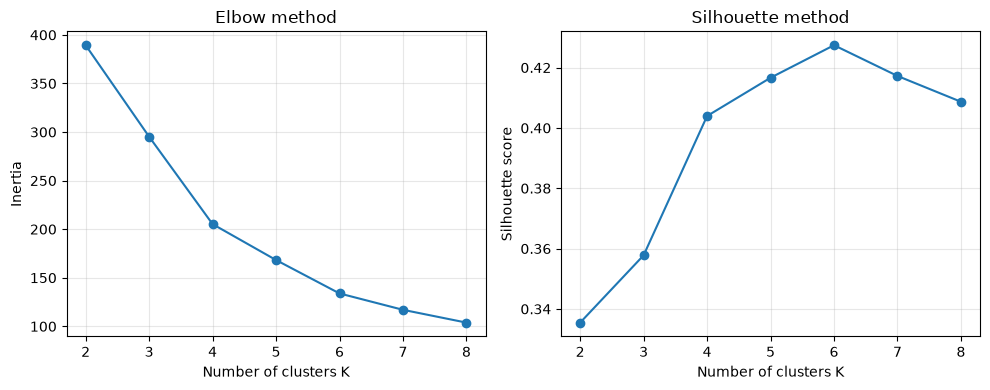

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters K")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
axes[0].set_xticks(ks)
axes[0].grid(alpha=0.3)

axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters K")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette method")
axes[1].set_xticks(ks)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
CHOSEN_K = 5

kmeans = KMeans(
    n_clusters=CHOSEN_K,
    n_init=30,
    random_state=42,
)

k_labels = kmeans.fit_predict(X)
kmeans_silhouette = silhouette_score(X, k_labels)

segments = customers.copy()
segments["kmeans_cluster"] = k_labels

profile = (
    segments.groupby("kmeans_cluster")[features]
    .mean()
    .round(1)
)

profile["customers"] = (
    segments["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

print("K-means silhouette:", round(kmeans_silhouette, 4))
display(profile)

K-means silhouette: 0.4166


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Age,Annual Income (k$),Spending Score (1-100),customers
kmeans_cluster,,,,
0,46.2,26.8,18.4,20
1,25.2,41.1,62.2,54
2,32.9,86.1,81.5,40
3,39.9,86.1,19.4,39
4,55.6,54.4,48.9,47


In [7]:
def evaluate_dbscan(X, eps, min_samples=6):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X)

    clustered = labels != -1
    n_clustered = int(clustered.sum())
    n_clusters = len(set(labels[clustered]))
    n_noise = int((~clustered).sum())

    score = np.nan

    if 2 <= n_clusters < n_clustered:
        score = silhouette_score(
            X[clustered],
            labels[clustered],
        )

    result = {
        "Method": "DBSCAN",
        "eps": eps,
        "Clusters": n_clusters,
        "Noise points": n_noise,
        "Coverage (%)": 100 * n_clustered / len(X),
        "Silhouette": score,
    }

    return labels, result


d_labels_075, result_075 = evaluate_dbscan(X, eps=0.75)
d_labels_050, result_050 = evaluate_dbscan(X, eps=0.5)

comparison = pd.DataFrame([
    {
        "Method": "K-means",
        "eps": np.nan,
        "Clusters": CHOSEN_K,
        "Noise points": 0,
        "Coverage (%)": 100.0,
        "Silhouette": kmeans_silhouette,
    },
    result_075,
    result_050,
])

display(comparison.round(4))

print(
    "DBSCAN silhouette excludes noise points. "
    "NaN means a valid silhouette could not be calculated."
)

,Method,eps,Clusters,Noise points,Coverage (%),Silhouette
0,K-means,NaN,5,0,100.0,0.4166
1,DBSCAN,0.75,1,14,93.0,NaN
2,DBSCAN,0.50,5,66,67.0,0.5278


DBSCAN silhouette excludes noise points. NaN means a valid silhouette could not be calculated.


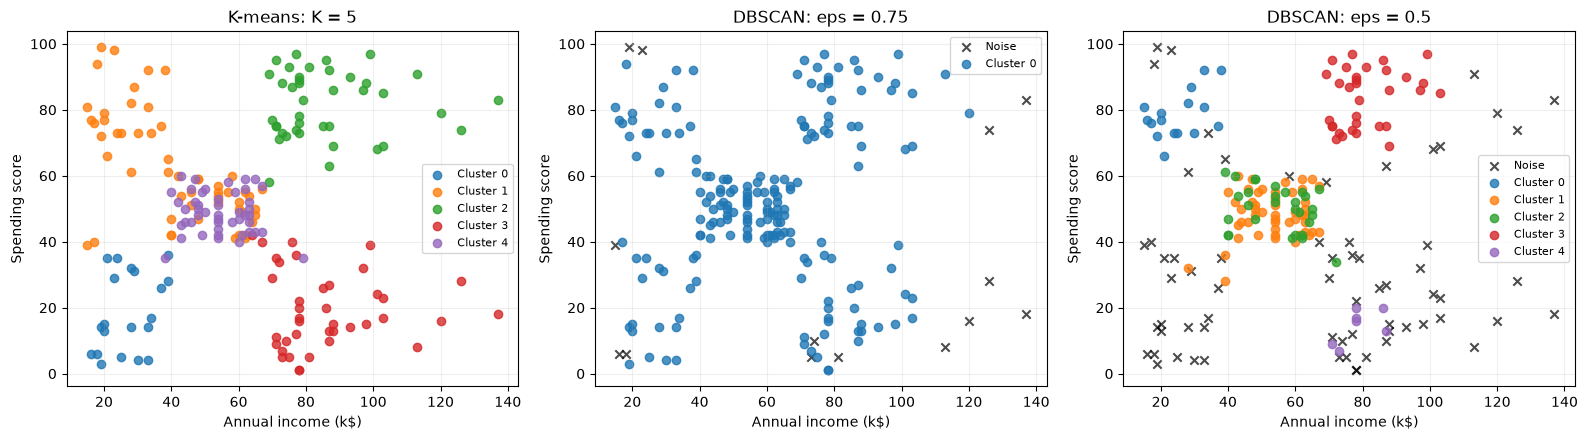

Clustering uses age, income, and spending score; these plots display only income and spending score.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

panels = [
    (axes[0], k_labels, "K-means: K = 5"),
    (axes[1], d_labels_075, "DBSCAN: eps = 0.75"),
    (axes[2], d_labels_050, "DBSCAN: eps = 0.5"),
]

for ax, labels, title in panels:
    for label in sorted(np.unique(labels)):
        mask = labels == label

        if label == -1:
            ax.scatter(
                customers.loc[mask, "Annual Income (k$)"],
                customers.loc[mask, "Spending Score (1-100)"],
                color="black",
                marker="x",
                label="Noise",
                alpha=0.7,
            )
        else:
            ax.scatter(
                customers.loc[mask, "Annual Income (k$)"],
                customers.loc[mask, "Spending Score (1-100)"],
                color=plt.get_cmap("tab10")(int(label) % 10),
                label=f"Cluster {label}",
                alpha=0.8,
            )

    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(
    "Clustering uses age, income, and spending score; "
    "these plots display only income and spending score."
)

In [9]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"

columns = [f"pixel_{i}" for i in range(64)] + ["label"]

with zipfile.ZipFile(archive_path) as archive:
    members = {
        Path(name).name: name
        for name in archive.namelist()
        if not name.endswith("/")
    }

    required_members = ["optdigits.tra", "optdigits.tes"]

    for name in required_members:
        if name not in members:
            raise FileNotFoundError(
                f"{name} was not found inside the ZIP."
            )

    with archive.open(members["optdigits.tra"]) as file:
        train = pd.read_csv(
            file,
            header=None,
            names=columns,
        )

    with archive.open(members["optdigits.tes"]) as file:
        test = pd.read_csv(
            file,
            header=None,
            names=columns,
        )

X_dev = train.drop(columns="label") / 16.0
y_dev = train["label"]

X_test = test.drop(columns="label") / 16.0
y_test = test["label"]

print("Training digits:", len(X_dev))
print("Test digits:", len(X_test))
print("Features per digit:", X_dev.shape[1])

display(train.head())

Training digits: 3823
Test digits: 1797
Features per digit: 64


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,label
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


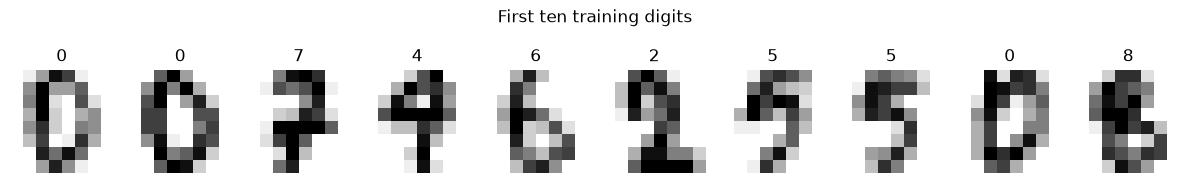

In [10]:
fig, axes = plt.subplots(1, 10, figsize=(12, 2))

for i, ax in enumerate(axes):
    image = X_dev.iloc[i].to_numpy().reshape(8, 8)

    ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(str(y_dev.iloc[i]))
    ax.axis("off")

plt.suptitle("First ten training digits")
plt.tight_layout()
plt.show()

In [11]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev,
)

baseline = LogisticRegression(max_iter=2000)
baseline.fit(X_fit, y_fit)

validation_rows = [{
    "Representation": "All 64 pixels",
    "Components": 64,
    "Validation accuracy": accuracy_score(
        y_valid,
        baseline.predict(X_valid),
    ),
}]

for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        (
            "pca",
            PCA(
                n_components=retained_variance,
                svd_solver="full",
            ),
        ),
        ("model", LogisticRegression(max_iter=2000)),
    ])

    candidate.fit(X_fit, y_fit)

    validation_rows.append({
        "Representation": f"PCA {retained_variance:.0%} variance",
        "Components": candidate.named_steps["pca"].n_components_,
        "Validation accuracy": accuracy_score(
            y_valid,
            candidate.predict(X_valid),
        ),
    })

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

,Representation,Components,Validation accuracy
0,All 64 pixels,64,0.9550
1,PCA 90% variance,21,0.9487
2,PCA 95% variance,29,0.9540
3,PCA 99% variance,41,0.9561


In [12]:
final_model = Pipeline([
    (
        "pca",
        PCA(
            n_components=0.95,
            svd_solver="full",
        ),
    ),
    ("model", LogisticRegression(max_iter=2000)),
])

final_model.fit(X_dev, y_dev)

full_model = LogisticRegression(max_iter=2000)
full_model.fit(X_dev, y_dev)

pca = final_model.named_steps["pca"]

full_predictions = full_model.predict(X_test)
pca_predictions = final_model.predict(X_test)

full_test_accuracy = accuracy_score(y_test, full_predictions)
pca_test_accuracy = accuracy_score(y_test, pca_predictions)

test_results = pd.DataFrame([
    {
        "Model": "All pixels + logistic regression",
        "Features / components": 64,
        "Test accuracy": full_test_accuracy,
    },
    {
        "Model": "95% PCA + logistic regression",
        "Features / components": pca.n_components_,
        "Test accuracy": pca_test_accuracy,
    },
])

print("FINAL RESULTS: official test file")
display(test_results.round(4))

print(
    "Variance retained:",
    round(pca.explained_variance_ratio_.sum(), 4),
)

print(
    "Reduction in number of features:",
    f"{100 * (1 - pca.n_components_ / 64):.1f}%",
)

print(
    "PCA minus full-model accuracy:",
    f"{100 * (pca_test_accuracy - full_test_accuracy):+.2f} "
    "percentage points",
)

FINAL RESULTS: official test file


,Model,Features / components,Test accuracy
0,All pixels + logistic regression,64,0.9477
1,95% PCA + logistic regression,29,0.9477


Variance retained: 0.9537
Reduction in number of features: 54.7%
PCA minus full-model accuracy: +0.00 percentage points


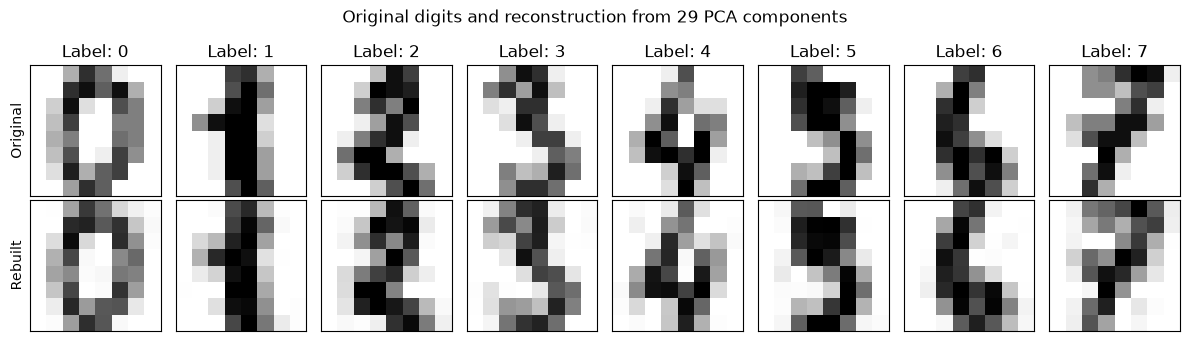

Reconstruction MSE for these eight digits: 0.003444


In [13]:
first_eight = X_test.head(8)

reconstructed = pca.inverse_transform(
    pca.transform(first_eight)
)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for j in range(8):
    axes[0, j].imshow(
        first_eight.iloc[j].to_numpy().reshape(8, 8),
        cmap="gray_r",
        vmin=0,
        vmax=1,
    )

    axes[1, j].imshow(
        reconstructed[j].reshape(8, 8),
        cmap="gray_r",
        vmin=0,
        vmax=1,
    )

    axes[0, j].set_title(f"Label: {y_test.iloc[j]}")
    axes[0, j].set_xticks([])
    axes[0, j].set_yticks([])
    axes[1, j].set_xticks([])
    axes[1, j].set_yticks([])

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Rebuilt")

plt.suptitle(
    f"Original digits and reconstruction from "
    f"{pca.n_components_} PCA components"
)
plt.tight_layout()
plt.show()

reconstruction_mse = np.mean(
    (first_eight.to_numpy() - reconstructed) ** 2
)

print(
    "Reconstruction MSE for these eight digits:",
    round(reconstruction_mse, 6),
)

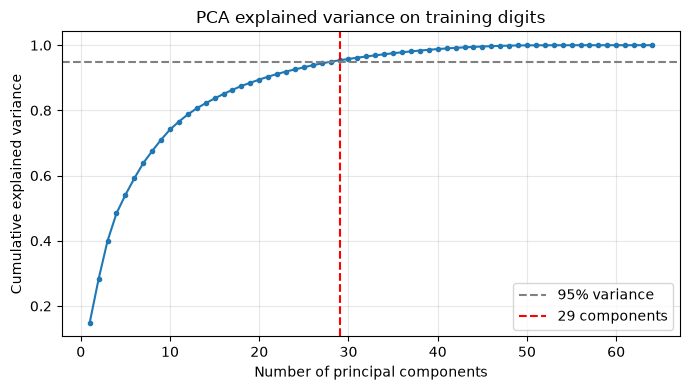

In [14]:
all_components = PCA(svd_solver="full")
all_components.fit(X_dev)

cumulative_variance = np.cumsum(
    all_components.explained_variance_ratio_
)

plt.figure(figsize=(7, 4))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker=".",
)

plt.axhline(
    0.95,
    linestyle="--",
    color="gray",
    label="95% variance",
)

plt.axvline(
    pca.n_components_,
    linestyle="--",
    color="red",
    label=f"{pca.n_components_} components",
)

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance on training digits")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
model_path = MODELS / "digits_pca_logistic.joblib"

joblib.dump(final_model, model_path)
loaded = joblib.load(model_path)

first_digits = X_test.iloc[:5]

loaded_predictions = loaded.predict(first_digits)
original_predictions = final_model.predict(first_digits)

prediction_check = pd.DataFrame({
    "Predicted": loaded_predictions,
    "Actual": y_test.iloc[:5].to_numpy(),
})

display(prediction_check)

assert np.array_equal(
    loaded_predictions,
    original_predictions,
), "Reloaded model predictions do not match."

print("Model saved to:", model_path)
print("File exists:", model_path.exists())
print("Reload verification passed.")
print("Input requirement: 64 pixel values scaled by dividing by 16.")

,Predicted,Actual
0,0,0
1,1,1
2,1,2
3,3,3
4,4,4


Model saved to: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\models\digits_pca_logistic.joblib
File exists: True
Reload verification passed.
Input requirement: 64 pixel values scaled by dividing by 16.


In [16]:
print("RESULTS FOR THE LAB DISCUSSION")
print("-" * 40)

print("\nPart A: K selection")
print(clustering_results.round(4).to_string(index=False))

print("\nPart B: clustering comparison")
print(comparison.round(4).to_string(index=False))

print("\nK-means customer profiles")
print(profile.to_string())

print("\nPart C: validation")
print(validation_results.round(4).to_string(index=False))

print("\nFinal test comparison")
print(test_results.round(4).to_string(index=False))

print("\nPCA components retained:", pca.n_components_)
print(
    "Variance retained:",
    round(pca.explained_variance_ratio_.sum(), 4),
)
print("Saved model exists:", model_path.exists())

RESULTS FOR THE LAB DISCUSSION
----------------------------------------

Part A: K selection
 K  Inertia  Silhouette
 2 389.3862      0.3355
 3 295.2122      0.3578
 4 205.2251      0.4040
 5 168.2476      0.4166
 6 133.8683      0.4274
 7 117.0116      0.4172
 8 103.8286      0.4087

Part B: clustering comparison
 Method  eps  Clusters  Noise points  Coverage (%)  Silhouette
K-means  NaN         5             0         100.0      0.4166
 DBSCAN 0.75         1            14          93.0         NaN
 DBSCAN 0.50         5            66          67.0      0.5278

K-means customer profiles
                 Age  Annual Income (k$)  Spending Score (1-100)  customers
kmeans_cluster                                                             
0               46.2                26.8                    18.4         20
1               25.2                41.1                    62.2         54
2               32.9                86.1                    81.5         40
3               39.9     

# Lab 4: Unsupervised Learning — Clustering and PCA

## Part A: Choosing the Number of Clusters

Age, annual income, and spending score were standardized before clustering. This prevents differences in feature scales from dominating the distance calculations.

Inertia decreased from **389.3862 at K = 2** to **103.8286 at K = 8**. The elbow plot shows a noticeable bend around **K = 4**, with smaller improvements as more clusters are added. The silhouette score reached its highest value of **0.4274 at K = 6**, compared with **0.4166 at K = 5**.

These results suggest considering several possible values rather than relying on one score. I used **K = 5**, following the activity, because it produces five interpretable customer groups while keeping the segmentation relatively simple. K = 6 has a slightly higher silhouette score, but its additional group would need to provide useful marketing information to justify the extra complexity.

### Customer Profiles

| Cluster | Customers | Mean age | Mean annual income (k$) | Mean spending score | Interpretation |
|---|---:|---:|---:|---:|---|
| 0 | 20 | 46.2 | 26.8 | 18.4 | Lower-income, low-spending customers |
| 1 | 54 | 25.2 | 41.1 | 62.2 | Younger customers with relatively high spending |
| 2 | 40 | 32.9 | 86.1 | 81.5 | High-income, high-spending customers |
| 3 | 39 | 39.9 | 86.1 | 19.4 | High-income, low-spending customers |
| 4 | 47 | 55.6 | 54.4 | 48.9 | Older customers with moderate income and spending |

These profiles could support different marketing strategies. For example, cluster 2 could be considered for loyalty rewards, while cluster 3 could be investigated to understand why spending is low despite high income. Cluster 0 could be considered for affordable offers. These are possible strategies to test; the clustering results alone do not establish which offers customers will respond to.

## Part B: Comparing K-means and DBSCAN

| Method | Parameters | Clusters | Noise points | Coverage | Silhouette |
|---|---|---:|---:|---:|---:|
| K-means | K = 5 | 5 | 0 | 100% | 0.4166 |
| DBSCAN | eps = 0.75, min_samples = 6 | 1 | 14 | 93% | Not defined |
| DBSCAN | eps = 0.50, min_samples = 6 | 5 | 66 | 67% | 0.5278 |

K-means assigned all 200 customers to five groups. DBSCAN with **eps = 0.75** produced one cluster containing 186 customers and classified 14 customers as noise. Its silhouette score was not defined because only one non-noise cluster was found. This result provides limited customer segmentation at this radius.

Reducing **eps to 0.50** produced five clusters, but increased the number of noise points to **66**, leaving only **67%** of customers assigned to clusters. A smaller radius makes the density requirement stricter, so fewer points remain connected.

The silhouette score of **0.5278** for DBSCAN at eps = 0.50 was higher than the K-means score of **0.4166**. However, the DBSCAN score was calculated only on non-noise customers, so it does not demonstrate better segmentation of the entire dataset.

For this marketing task, I prefer **K-means with K = 5** because it provides interpretable segments and assigns every customer to a group. Between the two DBSCAN settings, eps = 0.50 provides more useful segmentation than eps = 0.75, although the 66 unassigned customers would require separate investigation.

The scatter plots display income and spending score, while clustering also uses age. Therefore, groups that overlap in the plots may still differ in age.

## Part C: PCA and Digit Classification

The official training file was divided into fitting and validation sets. PCA was fitted only on the fitting data during validation. The official test file was reserved for the final comparison.

### Validation Results

| Representation | Features or components | Validation accuracy |
|---|---:|---:|
| All pixels | 64 | 95.50% |
| PCA retaining 90% variance | 21 | 94.87% |
| PCA retaining 95% variance | 29 | 95.40% |
| PCA retaining 99% variance | 41 | 95.61% |

Retaining more variance generally improved validation accuracy in these results. The 99% PCA setting achieved the highest validation accuracy, while the 95% setting performed almost as well as the full-pixel baseline using fewer components.

Following the activity, the final PCA setting was fixed at **95% retained variance**. Both models were then refitted using all official training rows.

### Final Test Results

| Model | Features or components | Test accuracy |
|---|---:|---:|
| Full pixels with logistic regression | 64 | 94.77% |
| PCA with logistic regression | 29 | 94.77% |

The final PCA model retained **29 components**, explaining approximately **95.37%** of training-data variance. This reduced the number of input dimensions by approximately **54.69%**, from 64 to 29.

Both models achieved the same test accuracy to four decimal places. This shows that substantial compression was possible without a measurable accuracy reduction at the reported precision. It does not necessarily mean that both models made identical predictions.

### Reconstruction Quality

The reconstructed digits retained their main shapes and remained visually recognizable. Compared with the originals, some edges were softer and some pixel intensities changed. This reflects the loss of detail when the remaining 35 components are discarded.

The reconstruction images and classification results together suggest that the retained components preserve much of the information useful for recognizing these digits.

### Saving and Reloading the Model

The PCA transformation and logistic regression classifier were saved together as `models/digits_pca_logistic.joblib`.

The file existed, and the reload verification passed. The reloaded pipeline reproduced the original pipeline's predictions for the five checked samples.

Its predictions were **[0, 1, 1, 3, 4]**, while the actual labels were **[0, 1, 2, 3, 4]**. Therefore, four of these five digits were classified correctly; the third digit was incorrectly predicted as 1 instead of 2.

Successful reload verification confirms that saving and loading preserved the model's behavior. It does not mean that every prediction is correct. New inputs must contain 64 pixel values scaled by dividing by 16, matching the training preprocessing.

## Check Your Understanding

### 1. What does PCA optimize when choosing its first principal component?

PCA selects the unit-length direction that maximizes the variance of the centered training data after projection onto that direction. It captures the greatest possible variation in a single component.

### 2. Why can standardization change which PCA directions appear most important?

PCA depends on feature variances and covariances. Features with larger numerical scales can dominate the principal components. Standardization changes their relative contributions by scaling each nonconstant feature to unit variance, which can change the directions PCA selects.

### 3. Why should distances and apparent cluster sizes in t-SNE or UMAP plots not be interpreted as exact properties of the original data?

t-SNE and UMAP compress high-dimensional data into fewer dimensions while emphasizing selected neighborhood relationships. This process distorts some distances, densities, and global relationships. Apparent cluster sizes and gaps also depend on the method and its parameters, so they should not be treated as exact measurements of the original data.